# Finding and certifying an orthogonal partition counterexample

**A small computational companion to _Counterexamples and Symmetry for Uneven
Orthogonal Mass Partitions in the Plane_ (Leonardo Martínez-Sandoval).**

This notebook generates a **new** centrally symmetric 96-point configuration
by simulated annealing and checks it with **two independent exact verifiers**.
It also verifies the particular integer configuration used in the paper.

Choose **Restart Kernel → Run All**, with this notebook in the repository root.
Install dependencies first with `python -m pip install -r requirements.txt`.
The search budget is four minutes; it stops as soon as a certified candidate is
found. The calibrated seed took about four seconds of search on our test machine.
JIT compilation and exact verification take additional time.
A different seed may fail within the budget: this is a heuristic search.

Every successful run actually starts from a fresh irregular ring. Saved
candidates are included for comparison and do not supply the search's initial state.

In [1]:
from pathlib import Path
import json
import math
import time
import inspect
import platform
import hashlib
import importlib.metadata
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Code
from annealing import search, warm_up, save_candidate, anneal_chunk
from verification import certify, save_report

ROOT = Path.cwd()
assert (ROOT / 'annealing.py').is_file(), 'Open the notebook in the repository root.'
OUTPUT = ROOT / 'outputs'
OUTPUT.mkdir(exist_ok=True)
versions = {name: importlib.metadata.version(name)
            for name in ('numpy', 'numba', 'matplotlib', 'nbformat', 'ipykernel')}
print('Python:', platform.python_version())
print('Dependencies:', versions)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})

Python: 3.12.12
Dependencies: {'numpy': '2.3.5', 'numba': '0.68.0', 'matplotlib': '3.10.8', 'nbformat': '5.11.1', 'ipykernel': '7.4.0'}


## 1. Turn a geometric partition into a rank condition

Write $N=2m=96$, $k=8$, and
$$P=\{p_1,\ldots,p_m,-p_1,\ldots,-p_m\}.$$
We seek two perpendicular lines with cyclic sector sizes $(k,k,m-k,m-k)$.
For a unit cap normal $n=(\cos\theta,\sin\theta)$ and
$Jn=(-\sin\theta,\cos\theta)$, let
$$A=\operatorname{Top}_{m}(Jn),\qquad
B=\operatorname{Top}_{2k}(n),\qquad q_P(\theta)=|A\cap B|.$$
Here $\operatorname{Top}_s(v)$ selects the $s$ largest projections onto $v$.
One line bisects the points, and the other bounds a cap containing $2k$ points.
The four sector counts are
$$(q,\ m-q,\ m-2k+q,\ 2k-q).$$
Thus the desired partition exists exactly when $q=k$: the counts then are
$(k,m-k,m-k,k)$, a cyclic rotation of the requested order.
At tied cutoffs, all admissible choices must be considered.

For a generic direction, central symmetry gives a useful shortcut. Sort the
representatives by $|p_i\cdot n|$. Each of the first $2k$ representatives supplies
one point to $B$, and it belongs to $A$ exactly when
$$(p_i\cdot n)(p_i\cdot Jn)>0.$$
Also $q_P(\theta+\pi)=q_P(\theta)$, so the search sweeps only a half-circle.

In [2]:
def overlap_at_direction(points, theta, k):
    """Direct projection calculation for illustration; not the search kernel."""
    points = np.asarray(points, dtype=float)
    n = np.array([np.cos(theta), np.sin(theta)])
    u = np.array([-np.sin(theta), np.cos(theta)])
    A = set(np.argsort(-(points @ u))[:len(points)//2])
    B = set(np.argsort(-(points @ n))[:2*k])
    return len(A & B)

m, k = 48, 8
print(f'Target cyclic counts: ({k}, {k}, {m-k}, {m-k})')

Target cyclic counts: (8, 8, 40, 40)


## 2. Search for a one-sided barrier

We aim for $q_P(\theta)\ge k+1=9$ in every open directional chamber. This
excludes the target value $q_P(\theta)=8$. Penalize violations by
$$E(P)=\sum_{C}\bigl[\max\{0,k+1-q_P(C)\}\bigr]^2.$$
The energy is nonnegative and vanishes precisely when the desired one-sided
barrier holds on all sampled chambers of the floating-point sweep.

The search uses an event sweep, not an angular grid. Between events, projection
ranks and signs stay constant. An event either flips the sign contributed by one
representative or exchanges two adjacent absolute-projection ranks. These events
come from $p_i$, $Jp_i$, and $p_i\pm p_j$. Updating ranks and signs is cheaper
than repeatedly sorting all 96 points at every direction.

Following the historical C++ code, the initial chamber is also scored after
closing the half-circle, giving it one extra weight. This does not change the
zero-energy criterion. Coincident events or inconsistent adjacent-rank exchanges
receive a large numerical penalty.

**Zero search energy is only a candidate.** Floating-point event ordering and
integer rounding can fail. The exact verifiers below check the actual integer
coordinates, including every critical direction and every permitted boundary assignment.

## 3. Polar moves and the annealing schedule

At each step choose one representative uniformly. If it has polar coordinates
$(r,\alpha)$, propose
$$\alpha'=\alpha+sZ_1,\qquad r'=\operatorname{clip}(r e^{sZ_2},0.25,3),$$
where $Z_1,Z_2$ are independent standard normals. Its opposite point moves with it.
A proposal of energy $E'$ is accepted with probability
$$\min\{1,\exp((E-E')/T)\}.$$
Improvements are always accepted; occasionally accepting a worse proposal lets
the search escape a local minimum. This is an optimization heuristic, not a claim
of exact sampling from a Boltzmann distribution.

For phase $f=(\text{step}\bmod 20000)/20000$ use
$$T(f)=12(0.015)^f,\qquad s(f)=0.2(0.01)^f.$$
With probability $0.05$, replace $s(f)$ by $0.3$ to allow a larger move.
Both temperature and ordinary move size shrink during a cycle. Longer runs
reheat every 20,000 steps. Restarts use independently randomized irregular rings:
$$\alpha_i=(i+0.3Z_i)\pi/m,\qquad r_i=0.7+0.6U_i.$$

The next cell displays the actual Python loop used by the search. Numba compiles
it at runtime so that the same readable source can handle many event sweeps.

In [3]:
display(Code(inspect.getsource(anneal_chunk.py_func), language='python'))

@njit(cache=True)
def anneal_chunk(points, energy, best_points, best_energy, k, start, count, seed,
                 cycle_steps=20000):
    """Run a bounded chunk so Python can report progress and enforce a budget."""
    np.random.seed(seed)
    accepted = 0
    for offset in range(count):
        step = start + offset
        phase = (step % cycle_steps) / cycle_steps
        temperature = 12.0 * 0.015 ** phase
        scale = 0.2 * 0.01 ** phase
        if np.random.random() < 0.05:
            scale = 0.3
        i = np.random.randint(len(points))
        x, y = points[i]
        angle = math.atan2(y, x) + scale * np.random.normal()
        radius = math.hypot(x, y) * math.exp(scale * np.random.normal())
        radius = min(3.0, max(0.25, radius))
        points[i, 0] = radius * math.cos(angle)
        points[i, 1] = radius * math.sin(angle)
        proposal_energy = sweep_energy(points, k)
        if (proposal_energy <= energy or
                np.random.random() < math.exp((energy - proposal_energy) / temperature)):
            energy = proposal_energy
            accepted += 1
            if energy < best_energy:
                best_energy = energy
                best_points[:] = points
        else:
            points[i, 0], points[i, 1] = x, y
        if energy == 0:
            return energy, best_energy, offset + 1, accepted
    return energy, best_energy, count, accepted

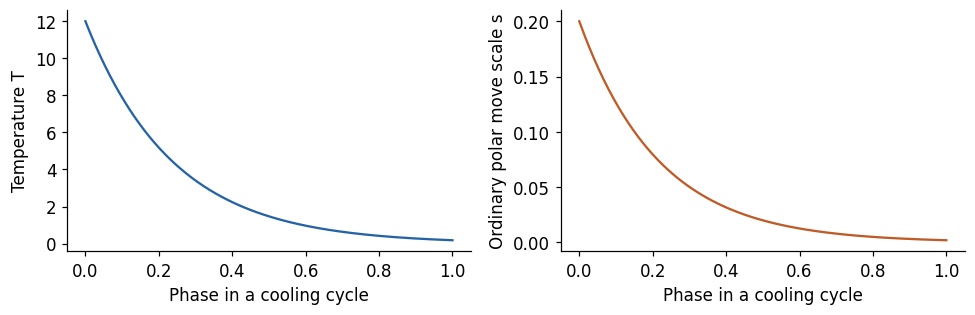

In [4]:
phase = np.linspace(0, 1, 300)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(phase, 12 * 0.015**phase, color='#2563a6')
axes[0].set(xlabel='Phase in a cooling cycle', ylabel='Temperature T')
axes[1].plot(phase, 0.2 * 0.01**phase, color='#bf5b27')
axes[1].set(xlabel='Phase in a cooling cycle', ylabel='Ordinary polar move scale s')
fig.tight_layout()
plt.show()

## 4. Find and certify a new example

Compile the Python kernels once before timing the search. The default seed **5**
was selected during calibration; it is not an estimate of success probability
for random seeds. Under the recorded dependencies it found a candidate after
16,947 proposals. This generator differs from the historical C++ generator.

The routine processes proposals in chunks so it can report progress and enforce
a wall-clock budget. Seed, chunk size, parameters, and dependency versions are
recorded. Changing chunk size changes the random trajectory.
The four-minute budget applies to the search; compilation and certification are
additional. A search chunk may slightly overrun the remaining budget.

The loop below rounds a zero-energy candidate and runs **both** exact verifiers.
If rounding invalidates it, or a seed exhausts its restart budget, it tries the
next seed while search time remains. It never substitutes a saved candidate for
a failed search.

In [5]:
started = time.monotonic()
warm_up()
print(f'Kernel warm-up: {time.monotonic() - started:.2f} seconds')

Kernel warm-up: 13.62 seconds


In [6]:
SEED = 5
SEARCH_SECONDS = 240
STEPS_PER_RESTART = 20_000
RESTARTS_PER_ATTEMPT = 6
CHUNK_SIZE = 1_000

search_time_used = 0.0
attempt = 0
attempt_log = []
new_report = None
while search_time_used < SEARCH_SECONDS:
    seed = SEED + attempt
    print(f'\nFresh search with seed {seed}')
    result = search(seed=seed, m=m, k=k,
                    steps_per_restart=STEPS_PER_RESTART,
                    restarts=RESTARTS_PER_ATTEMPT,
                    chunk_size=CHUNK_SIZE,
                    max_seconds=SEARCH_SECONDS - search_time_used)
    search_time_used += result.elapsed_seconds
    attempt_log.append({'seed': seed, 'best_energy': result.energy,
                        'proposals': result.steps,
                        'elapsed_seconds': result.elapsed_seconds})
    if result.energy == 0:
        candidate = save_candidate(result, OUTPUT / 'new_candidate.json', k=k)
        try:
            new_report = certify(candidate['points'], k)
        except (ValueError, AssertionError) as error:
            # Rounding can introduce duplicate points or other degeneracies.
            print(f'Rounded candidate rejected: {error}')
            new_report = {'certified': False, 'rejection_reason': str(error)}
        save_report(new_report, OUTPUT / 'new_certificate.json')
        if new_report['certified']:
            break
        print('The rounded candidate failed exact certification; continuing.')
    attempt += 1
else:
    raise RuntimeError('No certified example within the search budget. '
                       'Increase SEARCH_SECONDS or change SEED and rerun; '
                       'the independent paper-example cell can still be run.')

assert new_report is not None and new_report['certified']
print(f'\nNew example certified after {search_time_used:.2f}s of search.')
print('First representative:', candidate['points'][0])


Fresh search with seed 5
restart 1/6, step  1000, best E=1053, elapsed 0.2s
restart 1/6, step  5000, best E=308, elapsed 0.9s
restart 1/6, step 10000, best E=76, elapsed 1.9s
restart 1/6, step 15000, best E=3, elapsed 2.8s
restart 1/6, step 16947, best E=0, elapsed 3.1s
Exact ray/chamber verifier...
Independent rational-slope verifier...
Certified: True; 9,216 chambers; q-k histogram: {1: 8948, 2: 268}; weak event solutions: 0; elapsed 5.4s

New example certified after 3.12s of search.
First representative: [9535992, -2805451]


## 5. What does exact certification check?

The checker uses arbitrary-precision Python integers, not floating angles or
tolerances. For every difference $d=p_i-p_j$, critical normals are parallel or
perpendicular to $d$. These rays split the full direction circle into finitely
many open chambers. The ray checker uses the sum of consecutive primitive rays
as an integer normal lying strictly inside each chamber.

At a critical direction, tied projections can put points on a cutting line.
The first verifier enumerates one fixed-size tie choice and computes the extrema
of the overlap for the other. The second uses an independent dynamic program for
boundary assignments and rational-slope charts for open chambers. It imports
nothing from the first verifier. A certificate excludes both strict and weak
partitions, allowing boundary points to be assigned to any incident sector.

We also check distinctness, central symmetry, and **every** triple determinant.
These tests operate on the rounded coordinates, which are the actual asserted example.

In [7]:
print(json.dumps({
    'geometry': new_report['geometry'],
    'verifiers_agree': new_report['verifiers_agree'],
    'chambers': new_report['rays']['chamber_count'],
    'q_minus_k_histogram': new_report['rays']['defect_histogram'],
    'critical_defect_range': new_report['rays']['critical_defect_range'],
    'weak_solution_events': new_report['rays']['weak_solution_event_count'],
    'points_sha256': new_report['rays']['points_sha256'],
}, indent=2))

{
  "geometry": {
    "distinct_points": 96,
    "centrally_symmetric": true,
    "triples_checked": 142880,
    "collinear_triples": 0
  },
  "verifiers_agree": true,
  "chambers": 9216,
  "q_minus_k_histogram": {
    "1": 8948,
    "2": 268
  },
  "critical_defect_range": [
    1,
    2
  ],
  "weak_solution_events": 0,
  "points_sha256": "7745d0f3e70dfc87d6bf0b35ff88af1dc9dc4d667105b9de20e6ae209f57d207"
}


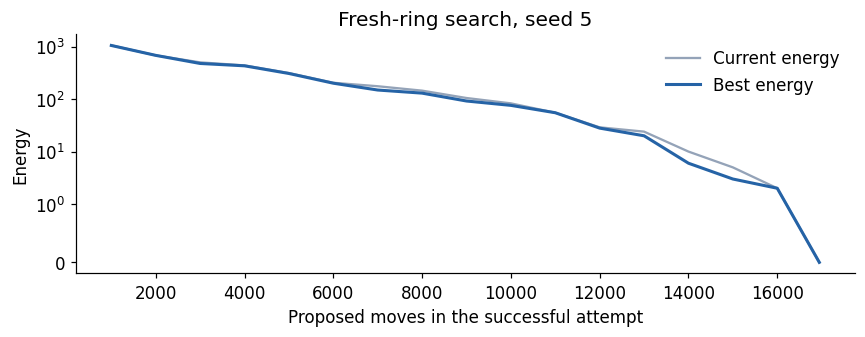

In [8]:
history = result.history
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot([h['proposals'] for h in history],
        [h['energy'] for h in history], color='#94a3b8', label='Current energy')
ax.plot([h['proposals'] for h in history],
        [h['best_energy'] for h in history], color='#2563a6', lw=2,
        label='Best energy')
ax.set_yscale('symlog', linthresh=1)
ax.set(xlabel='Proposed moves in the successful attempt', ylabel='Energy',
       title=f'Fresh-ring search, seed {result.seed}')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT / 'energy.png')
plt.show()

## 6. Independently verify the example in the article

This cell does not depend on the annealing outcome. The first representative is
$(6501822,-2132732)$. The expected certificate has **9,216 chambers**, with
$q-k=1$ in **8,814** and $q-k=2$ in **402**, and no weak solution at a critical
normal. Both verifiers must agree on the ordered-coordinate SHA-256 digest.

In [9]:
paper = json.loads((ROOT / 'data' / 'paper_example.json').read_text())
assert paper['points'][0] == [6501822, -2132732]
paper_report = certify(paper['points'], paper['k'])
assert paper_report['certified']
assert paper_report['rays']['chamber_count'] == 9216
assert paper_report['rays']['defect_histogram'] == {1: 8814, 2: 402}
assert paper_report['rays']['points_sha256'] == (
    '2b314645c5a8fd3f44b4334f539db860d658a5476ab2dff662e800ceabb18ed9')
save_report(paper_report, OUTPUT / 'paper_certificate.json')

Exact ray/chamber verifier...
Independent rational-slope verifier...
Certified: True; 9,216 chambers; q-k histogram: {1: 8814, 2: 402}; weak event solutions: 0; elapsed 3.8s


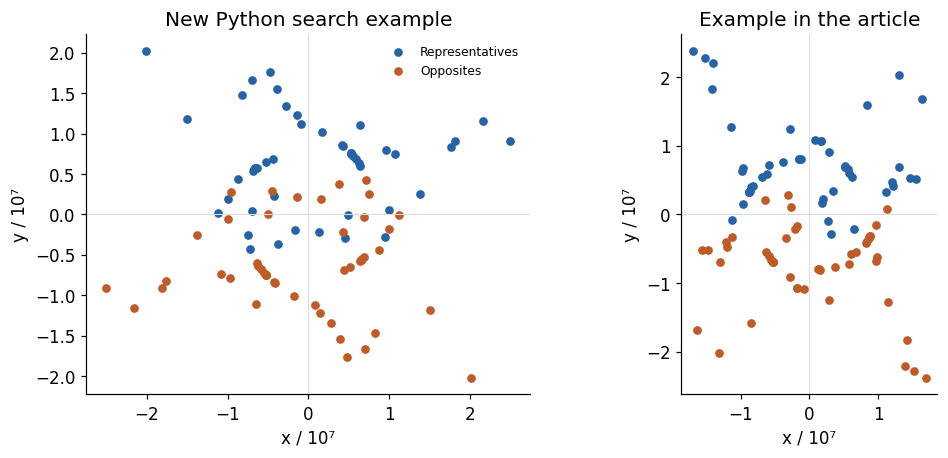

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, data, title in zip(axes, [candidate, paper],
                          ['New Python search example', 'Example in the article']):
    P = np.asarray(data['points'], dtype=float) / 1e7
    half = len(P)//2
    ax.scatter(P[:half, 0], P[:half, 1], s=22, color='#2563a6', label='Representatives')
    ax.scatter(P[half:, 0], P[half:, 1], s=22, color='#bf5b27', label='Opposites')
    ax.axhline(0, color='#ddd', lw=0.7)
    ax.axvline(0, color='#ddd', lw=0.7)
    ax.set_aspect('equal')
    ax.set(title=title, xlabel='x / 10⁷', ylabel='y / 10⁷')
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / 'examples.png')
plt.show()

## 7. Inspect the directional barrier and save the run

The next plot samples the overlap for illustration. It is **not** the certificate:
only the preceding exact sweeps and critical-direction checks exclude a partition.
Integer coordinates may be rescaled for plotting without changing the geometry.

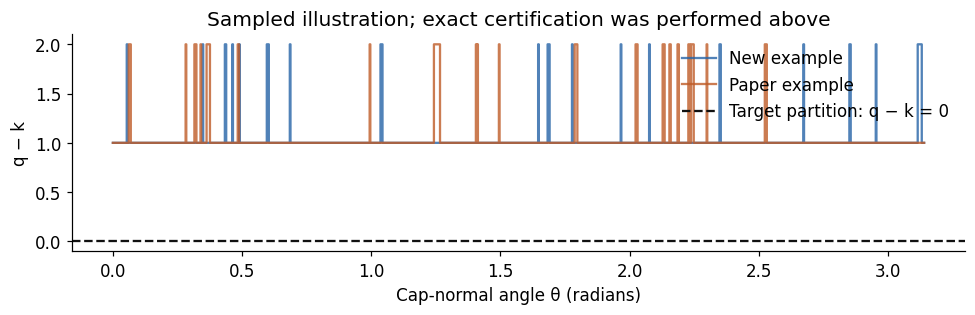

In [11]:
theta = np.linspace(0.000173, np.pi + 0.000173, 1200, endpoint=False)
fig, ax = plt.subplots(figsize=(9, 3))
for data, title, color in [(candidate, 'New example', '#2563a6'),
                          (paper, 'Paper example', '#bf5b27')]:
    overlap = [overlap_at_direction(data['points'], t, data['k']) - data['k']
               for t in theta]
    ax.step(theta, overlap, where='mid', color=color, alpha=0.8, label=title)
ax.axhline(0, color='#111', ls='--', label='Target partition: q − k = 0')
ax.set(xlabel='Cap-normal angle θ (radians)', ylabel='q − k',
       title='Sampled illustration; exact certification was performed above')
ax.legend(frameon=False, loc='upper right')
fig.tight_layout()
fig.savefig(OUTPUT / 'directional_barrier.png')
plt.show()

In [12]:
run_metadata = {
    'python': platform.python_version(), 'platform': platform.platform(),
    'dependencies': versions, 'attempts': attempt_log,
    'successful_search': candidate['search'],
    'search_time_seconds': search_time_used,
    'new_points_sha256': new_report['rays']['points_sha256'],
    'paper_points_sha256': paper_report['rays']['points_sha256'],
    'source_sha256': {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest()
                      for name in ('annealing.py', 'exact_verify.py',
                                   'slope_verify.py', 'verification.py')},
}
(OUTPUT / 'run_metadata.json').write_text(json.dumps(run_metadata, indent=2) + '\n')
print('Saved new coordinates, both certificates, figures, and run_metadata.json in outputs/.')
print('Both examples certified:', new_report['certified'] and paper_report['certified'])

Saved new coordinates, both certificates, figures, and run_metadata.json in outputs/.
Both examples certified: True


## Further experiments

Change `SEED`, the number of restarts, or the proposal budget. Keep $0<2k<m$
for the one-sided central search. A failure to find energy zero within a finite
budget is not evidence that all configurations admit the partition.

The two standalone exact checkers need only the Python standard library:
```bash
python exact_verify.py data/paper_example.json --full
python slope_verify.py data/paper_example.json
```
The checked-in `data/python_example.json` records the calibrated Python result;
it is never read by the search. Historical command, provenance, and the observed
runtime are documented in `PROVENANCE.md`. These computations do not establish
that 96 is the smallest possible number of points or that $k=8$ is minimal.